In [10]:
!pip uninstall -y gym gymnasium && !pip install gymnasium gym_bandits

Found existing installation: gym 0.25.2
Uninstalling gym-0.25.2:
  Successfully uninstalled gym-0.25.2
Found existing installation: gymnasium 1.3.0
Uninstalling gymnasium-1.3.0:
  Successfully uninstalled gymnasium-1.3.0
/bin/bash: line 1: !pip: command not found


In [11]:
import gymnasium as gym
import gym_bandits
import numpy as np

In [4]:
env = gym.make('MultiarmedBandits-v0')
print(env.observation_space)

Discrete(1)


/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


In [5]:
print(env.action_space)

Discrete(10)


In [7]:
import warnings

n_arms = env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_reward = []
action_history = []

warnings.filterwarnings("ignore", category = DeprecationWarning)

Estimated Q-values for each arm: [-0.7   0.06 -0.41 -0.13 -0.07 -0.8  -1.13  0.11 -0.09 -1.03]
Number of times each arm was selected: [  9 165  10  21 151   8   4 114  15   3]
Average reward over all episodes: -0.034


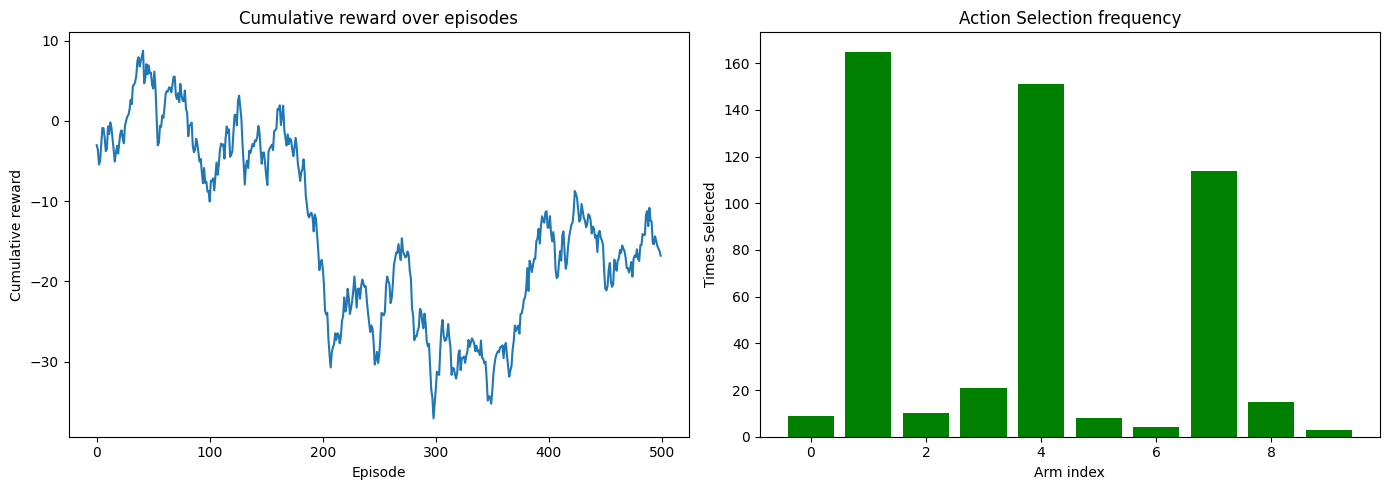

In [21]:
import warnings
import matplotlib.pyplot as plt # Added this import statement
n_arms = env.action_space.n
num_episodes = 500

epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards = []
action_history = []
warnings.filterwarnings("ignore", category=DeprecationWarning)
for episode in range(num_episodes):
    env.reset()
    if np.random.rand() < epsilon:
        action = env.action_space.sample()
    else:
        action = np.argmax(q_values)
    observation,reward,done,info = env.step(action)
    counts[action] += 1
    reward_sums[action] += reward
    q_values[action] = reward_sums[action] / counts[action]
    all_rewards.append(reward)
    action_history.append(action)

env.close()
print("Estimated Q-values for each arm:", np.round(q_values, 2))
print("Number of times each arm was selected:", counts.astype(int))
print("Average reward over all episodes:", round(np.mean(all_rewards), 3))
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(all_rewards)) # Changed to plot cumulative rewards
plt.title("Cumulative reward over episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative reward")

plt.subplot(1, 2, 2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title("Action Selection frequency")
plt.xlabel("Arm index")
plt.ylabel("Times Selected")

plt.tight_layout()
plt.show()